# Atelier 3 — Deep Learning & NLP arabe

**Partie 1** : classification de textes arabes (score de pertinence 0–10) avec RNN, BiRNN, GRU, LSTM (PyTorch)
**Partie 2** : fine-tuning d'un GPT-2 arabe + génération de texte

Plan : 1) Collecte → 2) Prétraitement → 3) Découpage & vocabulaire → 4) Modèles → 5) Tuning → 6) Évaluation → 7) BLEU / modèles de langue → **Partie 2 GPT-2** → Synthèse


## 0. Installation et imports

In [1]:
# torch, pandas, numpy, matplotlib, scikit-learn, transformers sont déjà dans Colab.
# (tensorflow n'est plus nécessaire : l'atelier est en PyTorch ; arabic-reshaper supprimé car inutilisé)
!pip install -q beautifulsoup4 nltk qalsadi

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re, time, random, copy, itertools
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from urllib.parse import urljoin
from bs4 import BeautifulSoup

import nltk
from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, f1_score)

nltk.download("stopwords", quiet=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

Device : cuda


## 1. Collecte des données (scraping)

**Ce qu'il faut viser** : 16 textes, c'est trop peu pour entraîner un RNN. Objectif : **60 à 100 articles** (≥ 15 par classe).
- Ajoute des articles **partiellement pertinents** (score 4–6) : technologie, données, robotique, cybersécurité… Ton dataset n'a actuellement aucun score entre 4 et 6.
- Prends aussi des articles **hors-sujet issus des mêmes sites** (Al Jazeera, BBC Arabic…), sinon le modèle apprendra à reconnaître *le site* (style Wikipedia/Mawdoo3) et non *le sujet*.
- Définis une grille de notation écrite (dans ton README) : ex. 9–10 = entièrement sur l'IA, 7–8 = IA importante mais mélangée, 4–6 = tech/données sans IA centrale, 1–3 = mention anecdotique, 0 = hors-sujet.

In [4]:

# Format : site, url, score (0-10)
# Grille de notation : voir README.md

articles = [

    # ==================================================
    # PERTINENTS (7-10) : IA au centre
    # ==================================================

    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/health/2026/9/29/%d8%a7%d9%84%d8%b0%d9%83%d8%a7%d8%a1-%d8%a7%d9%84%d8%a7%d8%b5%d8%b7%d9%86%d8%a7%d8%b9%d9%8a-%d9%81%d9%8a-%d8%a7%d9%84%d8%b7%d8%a8-%d9%85%d8%b3%d8%a7%d8%b9%d8%af%d8%a9-%d8%a3%d9%85", "score": 9},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/encyclopedia/2016/6/6/%D8%A7%D9%84%D8%B0%D9%83%D8%A7%D8%A1-%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A-%D8%AD%D9%8A%D9%86%D9%85%D8%A7-%D8%AA%D9%81%D9%83%D8%B1-%D8%A7%D9%84%D8%A2%D9%84%D8%A9", "score": 10},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/tech/2026/11/3/%D9%85%D8%A7%D8%B0%D8%A7-%D9%84%D9%88-%D8%B7%D9%88%D8%B1-%D8%A7%D9%84%D8%B0%D9%83%D8%A7%D8%A1-%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A-%D9%86%D9%81%D8%B3%D9%87", "score": 10},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/ebusiness/2026/11/16/%d8%a7%d9%84%d9%85%d8%b1%d9%83%d8%b2%d9%8a-%d8%a7%d9%84%d8%a3%d9%88%d8%b1%d9%88%d8%a8%d9%8a-%d9%88%d8%a7%d9%84%d9%81%d8%af%d8%b1%d8%a7%d9%84%d9%8a-%d8%a7%d9%84%d8%a3%d9%85%d8%b1%d9%8a%d9%83%d9%8a", "score": 9},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/ebusiness/2025/11/19/10-%D8%A2%D8%AB%D8%A7%D8%B1-%D8%B3%D9%84%D8%A8%D9%8A%D8%A9-%D9%84%D9%84%D8%B0%D9%83%D8%A7%D8%A1-%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A-%D8%B9%D9%84%D9%89", "score": 9},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%A7%D9%84%D8%B0%D9%83%D8%A7%D8%A1_%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A_%D9%81%D9%8A_%D8%A7%D9%84%D8%AA%D8%B9%D9%84%D9%8A%D9%85", "score": 9},
    {"site": "Mawdoo3", "url": "https://tech.mawdoo3.com/b/%D9%85%D8%B9%D9%84%D9%88%D9%85%D8%A7%D8%AA-%D8%B9%D9%86-%D8%A7%D9%84%D8%B0%D9%83%D8%A7%D8%A1-%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A-%D8%A7%D9%84%D8%AA%D9%88%D9%84%D9%8A%D8%AF%D9%8A", "score": 10},
    {"site": "Mawdoo3", "url": "https://tech.mawdoo3.com/b/%D8%A3%D8%A8%D8%B1%D8%B2-%D9%85%D8%AC%D8%A7%D9%84%D8%A7%D8%AA-%D8%A7%D8%B3%D8%AA%D8%AE%D8%AF%D8%A7%D9%85-%D8%A7%D9%84%D8%B1%D9%88%D8%A8%D9%88%D8%AA%D8%A7%D8%AA", "score": 7},
    {"site": "Mawdoo3", "url": "https://tech.mawdoo3.com/b/%D8%A3%D8%A8%D8%B1%D8%B2-%D8%AA%D8%B7%D8%A8%D9%8A%D9%82%D8%A7%D8%AA-%D8%A7%D9%84%D8%B0%D9%83%D8%A7%D8%A1-%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A-%D9%81%D9%8A-%D8%A7%D9%84%D8%B7%D8%A8", "score": 10},
    {"site": "BBC", "url": "https://www.bbc.com/arabic/articles/c5yv2pwwqppo", "score": 9},
    {"site": "IBM", "url": "https://www.ibm.com/sa-ar/think/insights/impact-of-ai", "score": 9},
    {"site": "IBM", "url": "https://www.ibm.com/ae-ar/think/topics/artificial-intelligence-types", "score": 10},
    {"site": "AWS", "url": "https://aws.amazon.com/ar/what-is/artificial-intelligence/", "score": 10},
    {"site": "Bakkah", "url": "https://bakkah.com/ar/knowledge-center/%D8%A7%D9%84%D8%B0%D9%83%D8%A7%D8%A1-%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A", "score": 10},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%A7%D9%84%D8%B0%D9%83%D8%A7%D8%A1_%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A_%D9%81%D9%8A_%D8%A7%D9%84%D9%85%D8%AC%D8%A7%D9%84_%D8%A7%D9%84%D8%B5%D8%AD%D9%8A", "score": 9},
    {"site": "IBM", "url": "https://www.ibm.com/sa-ar/think/topics/machine-learning", "score": 9},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%B0%D9%83%D8%A7%D8%A1_%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A_%D8%AA%D9%88%D9%84%D9%8A%D8%AF%D9%8A", "score": 10},
    {"site": "ARSCO", "url": "https://arsco-ai.org/publications/1739", "score": 9},
    {"site": "Mohammed Aameri", "url": "https://www.mohammedaameri.com/blog/273", "score": 9},
    {"site": "EGYIN", "url": "https://www.egyin.com/article/146192/%D8%AA%D8%B7%D8%A8%D9%8A%D9%82%D8%A7%D8%AA-%D8%A7%D9%84%D8%B0%D9%83%D8%A7%D8%A1-%D8%A7%D9%84%D8%A7%D8%B5%D8%B7%D9%86%D8%A7%D8%B9%D9%8A-%D9%81%D9%8A-%D8%AE%D8%B7%D9%88%D8%B7-%D8%A7%D9%84%D8%A5%D9%86%D8%AA%D8%A7%D8%AC-%D8%AA%D8%B1%D9%81%D8%B9", "score": 9},

    # ==================================================
    # MOYENS (4-6) : technologies liées, IA non centrale
    # ==================================================

    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/encyclopedia/2024/9/19/%D8%A7%D9%84%D8%A3%D9%85%D9%86-%D8%A7%D9%84%D8%B3%D9%8A%D8%A8%D8%B1%D8%A7%D9%86%D9%8A-%D9%85%D9%81%D9%87%D9%88%D9%85%D9%87-%D9%88%D8%AA%D8%A7%D8%B1%D9%8A%D8%AE%D9%87", "score": 4},
    {"site": "IBM", "url": "https://www.ibm.com/ae-ar/think/topics/cloud-computing", "score": 4},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%A8%D9%8A%D8%A7%D9%86%D8%A7%D8%AA_%D8%B6%D8%AE%D9%85%D8%A9", "score": 5},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/encyclopedia/2016/8/24/%D8%A7%D9%84%D9%88%D8%A7%D9%82%D8%B9-%D8%A7%D9%84%D8%A7%D9%81%D8%AA%D8%B1%D8%A7%D8%B6%D9%8A-%D8%B9%D9%86%D8%AF%D9%85%D8%A7-%D9%86%D8%B9%D9%8A%D8%B4-%D8%A7%D9%84%D8%AE%D9%8A%D8%A7%D9%84", "score": 5},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/tech/2023/12/11/%D8%A7%D9%84%D8%B1%D9%88%D8%A8%D9%88%D8%AA-%D9%81%D9%8A-%D8%B2%D9%85%D9%86-%D8%A7%D9%84%D8%AA%D9%83%D9%86%D9%88%D9%84%D9%88%D8%AC%D9%8A%D8%A7-%D8%A7%D9%84%D8%B0%D9%87%D8%A8%D9%8A", "score": 5},
    {"site": "SAP", "url": "https://www.sap.com/mena-ar/resources/what-is-digital-transformation", "score": 6},
    {"site": "Bakkah", "url": "https://bakkah.com/ar/knowledge-center/automation", "score": 5},
    {"site": "Hsoub", "url": "https://academy.hsoub.com/programming/general/%D8%B9%D9%84%D9%85-%D8%A7%D9%84%D8%A8%D9%8A%D8%A7%D9%86%D8%A7%D8%AA/", "score": 5},
    {"site": "SAP", "url": "https://www.sap.com/mena-ar/resources/what-is-data-analytics", "score": 5},
    {"site": "AWS", "url": "https://aws.amazon.com/ar/what-is/intelligent-automation/", "score": 6},
    {"site": "AWS", "url": "https://aws.amazon.com/ar/what-is/bot/", "score": 5},
    {"site": "IBM", "url": "https://www.ibm.com/sa-ar/think/topics/software-development", "score": 5},
    {"site": "IdeaScale", "url": "https://ideascale.com/ar/%d8%a7%d9%84%d9%85%d8%af%d9%88%d9%86%d8%a9/%d9%85%d8%a7-%d9%87%d9%88-%d8%a7%d9%84%d8%a7%d8%a8%d8%aa%d9%83%d8%a7%d8%b1-%d8%a7%d9%84%d8%aa%d9%83%d9%86%d9%88%d9%84%d9%88%d8%ac%d9%8a/", "score": 5},
    {"site": "CyberOne", "url": "https://cyberone.co/%D8%B9%D9%86%D8%A7%D8%B5%D8%B1-%D8%A7%D9%85%D9%86-%D8%A7%D9%84%D9%85%D8%B9%D9%84%D9%88%D9%85%D8%A7%D8%AA/", "score": 4},
    {"site": "IBM", "url": "https://www.ibm.com/qa-ar/think/topics/it-security", "score": 5},
    {"site": "AWS", "url": "https://aws.amazon.com/ar/what-is-cloud-computing/", "score": 5},
    {"site": "SAP", "url": "https://www.sap.com/mena-ar/resources/what-is-iot", "score": 5},
    {"site": "IBM", "url": "https://www.ibm.com/qa-ar/think/topics/internet-of-things", "score": 5},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/blogs/2024/12/13/%D8%A5%D9%86%D8%AA%D8%B1%D9%86%D8%AA-%D8%A7%D9%84%D8%A3%D8%B4%D9%8A%D8%A7%D8%A1-%D8%AB%D9%88%D8%B1%D8%A9-%D8%AA%D9%83%D9%86%D9%88%D9%84%D9%88%D8%AC%D9%8A%D8%A9-%D8%AA%D8%BA%D9%8A%D8%B1", "score": 5},
    {"site": "ATTA", "url": "https://attaa.mcit.gov.sa/library/view/1251", "score": 5},

    # ==================================================
    # PEU PERTINENTS (0-3) : hors sujet
    # ==================================================

    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%A7%D9%82%D8%AA%D8%B5%D8%A7%D8%AF_%D8%A7%D9%84%D9%85%D8%BA%D8%B1%D8%A8", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%A7%D9%84%D8%B3%D9%8A%D8%A7%D8%AD%D8%A9_%D9%81%D9%8A_%D8%A7%D9%84%D9%85%D8%BA%D8%B1%D8%A8", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%B1%D9%8A%D8%A7%D8%B6%D8%A9", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D9%85%D8%B7%D8%A8%D8%AE_%D9%85%D8%BA%D8%B1%D8%A8%D9%8A", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%AA%D8%A7%D8%B1%D9%8A%D8%AE_%D8%A7%D9%84%D9%85%D8%BA%D8%B1%D8%A8", "score": 0},
    {"site": "Mawdoo3", "url": "https://mawdoo3.com/%D9%85%D9%81%D9%87%D9%88%D9%85_%D8%A7%D9%84%D8%B2%D8%B1%D8%A7%D8%B9%D8%A9_%D8%A7%D9%84%D8%AA%D9%82%D9%84%D9%8A%D8%AF%D9%8A%D8%A9", "score": 0},
    {"site": "Mawdoo3", "url": "https://mawdoo3.com/%D8%B9%D8%A7%D8%A6%D9%84%D8%A9_%D9%83%D8%A7%D8%AF%D9%8A%D9%84%D8%A7%D9%83_%D8%A5%D8%B3%D9%83%D8%A7%D9%84%D9%8A%D8%AF", "score": 0},
    {"site": "Mawdoo3", "url": "https://mawdoo3.com/%D9%85%D8%AC%D8%A7%D9%84%D8%A7%D8%AA_%D8%B9%D9%85%D9%84_%D8%AA%D8%AE%D8%B5%D8%B5_%D8%A3%D9%85%D9%86_%D8%A7%D9%84%D9%85%D8%B9%D9%84%D9%88%D9%85%D8%A7%D8%AA", "score": 3},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/news/liveblog/2026/11/18/%D8%A5%D9%8A%D8%B1%D8%A7%D9%86-%D9%85%D8%A8%D8%A7%D8%B4%D8%B1-%D9%82%D8%B5%D9%81-%D8%A3%D9%85%D8%B1%D9%8A%D9%83%D9%8A-%D9%81%D9%8A-%D8%AC%D8%B2%D9%8A%D8%B1%D8%A9-%D9%82%D8%B4%D9%85", "score": 0},
    {"site": "Al Jazeera", "url": "https://www.aljazeera.net/news/2026/11/18/%D9%85%D8%A7-%D8%A7%D9%84%D8%B0%D9%8A-%D9%8A%D8%AB%D9%8A%D8%B1-%D9%82%D9%84%D9%82-%D8%A3%D9%85%D8%B1%D9%8A%D9%83%D8%A7-%D9%81%D9%8A-%D8%A7%D9%84%D8%B3%D8%A7%D8%AD%D9%84", "score": 0},
    {"site": "Bashra", "url": "https://bshra.com/arabic/GguQ58Oj", "score": 0},
    {"site": "Bakkah", "url": "https://bakkah.com/ar/knowledge-center/%D8%A3%D9%81%D8%B6%D9%84-%D9%83%D8%AA%D8%A8-%D8%A5%D8%AF%D8%A7%D8%B1%D8%A9-%D8%A7%D9%84%D9%85%D8%B4%D8%A7%D8%B1%D9%8A%D8%B9-%D9%84%D9%84%D9%85%D8%A8%D8%AA%D8%AF%D8%A6%D9%8A%D9%86", "score": 0},
    {"site": "Selynk", "url": "https://selynk.com/%D8%A7%D9%84%D8%AD%D9%84%D9%88%D9%84-%D8%A7%D9%84%D8%B1%D9%82%D9%85%D9%8A%D8%A9/", "score": 3},
    {"site": "AS2", "url": "https://ar.as2.ae/what-is-a-gadget-its-uses-and-types/", "score": 2},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%A7%D9%84%D9%84%D8%BA%D8%A9_%D8%A7%D9%84%D8%B9%D8%B1%D8%A8%D9%8A%D8%A9", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D9%86%D9%87%D8%B1_%D8%A7%D9%84%D9%86%D9%8A%D9%84", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%A3%D8%AF%D8%A8_%D8%B9%D8%B1%D8%A8%D9%8A", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D9%85%D9%88%D8%B3%D9%8A%D9%82%D9%89", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D8%AD%D9%8A%D9%88%D8%A7%D9%86", "score": 0},
    {"site": "Wikipedia", "url": "https://ar.wikipedia.org/wiki/%D9%83%D8%B1%D8%A9_%D8%A7%D9%84%D9%82%D8%AF%D9%85", "score": 0}
]

# ==================================================
# VERIFICATION DES DONNEES
# ==================================================

print("Nombre total d'articles :", len(articles))
print("Pertinents (>=7) :", sum(a["score"] >= 7 for a in articles))
print("Moyens (4-6) :", sum(4 <= a["score"] <= 6 for a in articles))
print("Peu pertinents (0-3) :", sum(a["score"] <= 3 for a in articles))


Nombre total d'articles : 60
Pertinents (>=7) : 20
Moyens (4-6) : 20
Peu pertinents (0-3) : 20


In [5]:
HEADERS = {"User-Agent": "Mozilla/5.0"}

# recuperer le texte d un article a partir de son url
def extraire_texte(url, min_len_par=40):
    """Télécharge une page et renvoie le texte de ses paragraphes"""
    r = requests.get(url, headers=HEADERS, timeout=20)
    r.raise_for_status()
    r.encoding = "utf-8"
    soup = BeautifulSoup(r.text, "html.parser")
    for tag in soup(["script", "style", "nav", "footer", "header", "aside", "form", "noscript"]):
        tag.decompose()
    for tag in soup.select("sup.reference, .mw-editsection, .reflist"):    # Wikipedia : [1], [modifier], références
        tag.decompose()
    zone = soup.find("article") or soup.find("main") or soup.body
    paragraphes = [p.get_text(" ", strip=True) for p in zone.find_all("p")]
    texte = "\n".join(p for p in paragraphes if len(p) >= min_len_par)
    if len(texte) < 500:                                   # zone trop étroite -> on prend toute la page
        paragraphes = [p.get_text(" ", strip=True) for p in soup.find_all("p")]
        texte = "\n".join(p for p in paragraphes if len(p) >= min_len_par)
    return texte

# recuperer les urls
def collecter_liens(url_page, contient=None, max_liens=30):
    """Aide pour trouver rapidement de nouvelles URL d'articles"""
    r = requests.get(url_page, headers=HEADERS, timeout=20); r.encoding = "utf-8"
    soup = BeautifulSoup(r.text, "html.parser")
    liens = {urljoin(url_page, a["href"]) for a in soup.find_all("a", href=True)}
    if contient:
        liens = {l for l in liens if contient in l}
    return sorted(liens)[:max_liens]
# exemple : collecter_liens("https://www.aljazeera.net/tech/", contient="/tech/2026/")

Parcourir automatiquement tous les articles de la liste puis telecherger leur contenu et construire le dataset

In [6]:
resultats, echecs = [], []
for art in articles:
    try:
        texte = extraire_texte(art["url"])
        if len(texte) > 500:
            resultats.append({"Site": art["site"], "URL": art["url"], "Text": texte, "Score": art["score"]})
            print(f"OK  : {art['site']:<11} {len(texte):>6} caractères")
        else:
            echecs.append(art["url"]); print(f"Texte insuffisant : {art['site']}")
    except Exception as e:
        echecs.append(art["url"]); print(f"Erreur : {art['site']} - {e}")
    time.sleep(2)

df = pd.DataFrame(resultats)
df.to_csv("dataset_brut.csv", index=False, encoding="utf-8-sig")   # sauvegarde : évite de re-scraper lors de la deconnexion
print("\nRécupérés :", len(df), "| échecs :", len(echecs))

OK  : Al Jazeera   12758 caractères
OK  : Al Jazeera    9185 caractères
OK  : Al Jazeera    9036 caractères
OK  : Al Jazeera    3391 caractères
OK  : Al Jazeera   10068 caractères
OK  : Wikipedia    10852 caractères
OK  : Mawdoo3       2212 caractères
OK  : Mawdoo3       3400 caractères
OK  : Mawdoo3       3318 caractères
OK  : BBC           4058 caractères
OK  : IBM          25683 caractères
OK  : IBM          10854 caractères
OK  : AWS          23078 caractères
OK  : Bakkah       38925 caractères
OK  : Wikipedia     7309 caractères
OK  : IBM          23829 caractères
OK  : Wikipedia    31085 caractères
OK  : ARSCO         5185 caractères
OK  : Mohammed Aameri  23196 caractères
OK  : EGYIN         3906 caractères
OK  : Al Jazeera    9772 caractères
OK  : IBM          24019 caractères
OK  : Wikipedia    35392 caractères
OK  : Al Jazeera    4644 caractères
OK  : Al Jazeera    7580 caractères
Erreur : SAP - 403 Client Error: Forbidden for url: https://www.sap.com/mena-ar/resources/what-i

verifier la qualite du dataset creer

In [7]:
print("Dimensions du dataset :", df.shape)

print("\nNombre d'articles par score :")
print(df["Score"].value_counts().sort_index())

print("\nRépartition des classes :")
df["Classe"] = pd.cut(
    df["Score"],
    bins=[-1, 3, 6, 10],
    labels=["Peu pertinent", "Moyen", "Pertinent"]
)

print(df["Classe"].value_counts())

print("\nValeurs manquantes :")
print(df[["Text", "Score"]].isnull().sum())

print("\nLongueur des articles :")
print(df["Text"].str.len().describe())

Dimensions du dataset : (55, 4)

Nombre d'articles par score :
Score
0     16
2      1
3      2
4      3
5     12
6      1
7      1
9     11
10     8
Name: count, dtype: int64

Répartition des classes :
Classe
Pertinent        20
Peu pertinent    19
Moyen            16
Name: count, dtype: int64

Valeurs manquantes :
Text     0
Score    0
dtype: int64

Longueur des articles :
count       55.000000
mean     14723.800000
std      13966.609173
min       1564.000000
25%       4477.000000
50%       9185.000000
75%      23377.000000
max      65962.000000
Name: Text, dtype: float64


La répartition est relativement équilibrée. Aucune classe ne domine fortement les autres

In [8]:
# Si la session Colab a été réinitialisée : on recharge simplement le CSV
df = pd.read_csv("dataset_brut.csv")
print(df.shape)
display(df[["Site", "Text", "Score"]].head())
print(df.isnull().sum())

(55, 4)


,Site,Text,Score
0,Al Jazeera,الذكاء الاصطناعي يتعلم من البيانات التي قد تحم...,9
1,Al Jazeera,الذكاء الاصطناعي تعبير يطلق على القدرات التي ت...,10
2,Al Jazeera,"في فبراير/شباط 2026، أعلنت "" أوبن إيه آي "" أن ...",10
3,Al Jazeera,مسؤولون في البنك المركزي الأوروبي والاحتياطي ا...,9
4,Al Jazeera,الذكاء الاصطناعي له تأثير اقتصادي كبير متوقع (...,9


Site     0
URL      0
Text     0
Score    0
dtype: int64


### Discrétisation du score → classes
Le sujet demande une *classification* alors que le score est numérique : on le **discrétise** en classes (c'est l'étape « Discretization » du pipeline demandé).

Classe
pertinent (7-10)       20
peu_pertinent (0-3)    19
moyen (4-6)            16
Name: count, dtype: int64

Scores : {0: np.int64(16), 2: np.int64(1), 3: np.int64(2), 4: np.int64(3), 5: np.int64(12), 6: np.int64(1), 7: np.int64(1), 9: np.int64(11), 10: np.int64(8)}


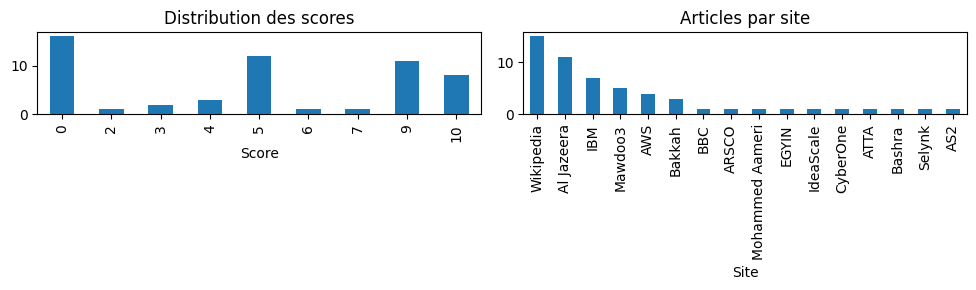

In [9]:
CLASSES_NOMS = {0: "peu_pertinent (0-3)", 1: "moyen (4-6)", 2: "pertinent (7-10)"}

def discretiser(score):
    if score <= 3:  return 0
    if score <= 6:  return 1
    return 2

df["Classe"] = df["Score"].apply(discretiser)

# On n'utilise que les classes réellement présentes -> ids 0..K-1
classes_presentes = sorted(df["Classe"].unique())
cls2id = {c: i for i, c in enumerate(classes_presentes)}
df["label"] = df["Classe"].map(cls2id)
noms_classes = [CLASSES_NOMS[c] for c in classes_presentes]
n_classes = len(classes_presentes)

print(df["Classe"].map(CLASSES_NOMS).value_counts())
print("\nScores :", dict(df["Score"].value_counts().sort_index()))
if n_classes < 3:
    print("\n⚠️ Il manque la classe « moyen » : ajoute des articles notés 4 à 6.")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df["Score"].value_counts().sort_index().plot.bar(ax=ax[0], title="Distribution des scores")
df["Site"].value_counts().plot.bar(ax=ax[1], title="Articles par site")
plt.tight_layout(); plt.show()

In [10]:
# (Optionnel) contrôle de cohérence de tes scores manuels : densité de mots-clés IA
MOTS_CLES_IA = ["الذكاء الاصطناعي", "تعلم الآلة", "التعلم العميق", "الشبكات العصبية", "خوارزمية", "روبوت", "نموذج لغوي"]
def score_auto(texte):
    n_mots = max(len(texte.split()), 1)
    hits = sum(texte.count(m) for m in MOTS_CLES_IA)
    return min(10, round(hits / n_mots * 1000 / 2, 1))      # heuristique : à calibrer, sert seulement de vérification

df["Score_auto"] = df["Text"].apply(score_auto)
print("Corrélation score manuel / score auto :", round(df["Score"].corr(df["Score_auto"]), 2))
display(df[["Site", "Score", "Score_auto"]].sort_values("Score"))

Corrélation score manuel / score auto : 0.85


,Site,Score,Score_auto
49,Wikipedia,0,0.0
50,Wikipedia,0,0.0
51,Wikipedia,0,0.0
52,Wikipedia,0,0.1
54,Wikipedia,0,0.0
53,Wikipedia,0,0.0
45,Bashra,0,0.0
46,Bakkah,0,0.4
40,Wikipedia,0,0.0
41,Mawdoo3,0,0.0


**Cependant, cette méthode automatique reste heuristique : la fréquence des mots-clés ne suffit pas à déterminer précisément la pertinence sémantique d'un article. Les scores manuels sont donc conservés comme références pour l'entraînement des modèles**

## 2. Pipeline de prétraitement NLP


1. **Les mots de bruit (« الجزيرة », « دقيقة »…) sont retirés AVANT la normalisation** — avant, `دقائق` devenait `دقايق` (ئ→ي) et n'était plus reconnu : ton texte nettoyé contenait encore « 4 دقايق ».
2. **Les stop words sont normalisés comme le texte** — avant, `على`, `إلى`, `أن`, `أو` devenaient `علي`, `الي`, `ان`, `او` et n'étaient plus filtrés : ce sont les 1ers mots de ton vocabulaire !
3. **On ne garde que les lettres arabes** (`ء-ي`) : avant, la virgule arabe `،` (dans la plage `؀-ۿ`) et les chiffres (`2024`, `16`) restaient dans les tokens, contrairement à ce que tu avais prévu.
4. **Ajout du stemming et de la lemmatisation**
stemming --> racine du mot
lemmatisation --> vers la forme de base lemme

In [11]:
DIACRITIQUES = re.compile(r"[ً-ٰٟ]")
# uniformiser les différentes écritures d'une même lettre arabe pour éviter de considérer des variantes comme des mots différents
# 1-Suppression des diacritiques 2-Suppression du Tatweel 3-Uniformisation de certaines lettres
def normaliser(t):
    t = DIACRITIQUES.sub("", t).replace("ـ", "")          # voyelles brèves + tatweel (ـ)
    t = re.sub("[إأآ]", "ا", t)
    return t.replace("ى", "ي").replace("ؤ", "و").replace("ئ", "ي")

# Suppression des mots de bruit
BRUIT = [r"https?://\S+|www\.\S+",
         r"الجزيرة\s+تصفح في التطبيق",
         r"وقت القراءة\s*:?\s*\d+\s*(?:دقيقة|دقائق)",
         r"\(\s*[أا]دوبي ستوك\s*\)",
         r"\bاستمع\b"]
def supprimer_bruit(t):
    for motif in BRUIT:
        t = re.sub(motif, " ", t)
    return t

# Liste des mots vides NLTK, normalisés
STOP = {normaliser(w) for w in stopwords.words("arabic")}

# Ajout de mots vides supplémentaires
STOP |= {normaliser(w) for w in [
    "يمكن", "خلال", "عام", "بشكل", "عبر", "العديد",
    "وفي", "وقد", "وهي", "وهو", "كما", "حيث"
]}

print("Stop words :", len(STOP))

# Fonction principale de nettoyage et tokenisation
def nettoyer_tokens(texte):
    t = supprimer_bruit(texte)
    t = normaliser(t)
    t = re.sub(r"[^ء-ي\s]", " ", t)                  # lettres arabes uniquement (plus de ponctuation ni chiffres)
    return [w for w in t.split() if w not in STOP and len(w) > 1]   # tokenisation + stop words

# test
print(nettoyer_tokens("أنا طالبٌ في الجامعة سنة 2025، وقت القراءة: 4 دقائق https://google.com"))

Stop words : 632
['طالب', 'الجامعة', 'سنة']


In [12]:
# Stemming (ISRI, intégré à NLTK) et lemmatisation (qalsadi). On traite le vocabulaire UNIQUE -> rapide.
df["tokens"] = df["Text"].apply(nettoyer_tokens)
vocab_unique = sorted({w for toks in df["tokens"] for w in toks})
print("Mots uniques :", len(vocab_unique))

isri = ISRIStemmer()
map_stem = {w: isri.stem(w) for w in vocab_unique}
# lemmatisation avec Qalsadi
try:
    from qalsadi.lemmatizer import Lemmatizer
    lemmer = Lemmatizer()
    map_lemma = {}
    for w in vocab_unique:
        try:    map_lemma[w] = normaliser(lemmer.lemmatize(w))
        except Exception: map_lemma[w] = w
except Exception as e:
    print("qalsadi indisponible -> lemmatisation remplacée par le stemming :", e)
    map_lemma = map_stem

df["tokens_stem"]  = df["tokens"].apply(lambda ts: [map_stem[w] for w in ts])
df["tokens_lemma"] = df["tokens"].apply(lambda ts: [map_lemma[w] for w in ts])

print("\nExemple (10 mots) :")
print(pd.DataFrame({"token": df.loc[0, "tokens"][20:30],
                    "stem":  df.loc[0, "tokens_stem"][20:30],
                    "lemme": df.loc[0, "tokens_lemma"][20:30]}).to_string(index=False))

tailles = {v: len({w for toks in df[v] for w in toks}) for v in ["tokens", "tokens_stem", "tokens_lemma"]}
print("\nTaille du vocabulaire :", tailles)

Mots uniques : 22697

Exemple (10 mots) :
   token     stem    lemme
   عملية      عمل     عملة
   اتخاذ      تخذ    اتخاذ
  القرار      قرر     قارر
خوارزمية خوارزمية خوارزمية
   تقترح      قرح    اقترح
  تشخيصا      شخص    تشخيص
    تحدد      حدد     تحدد
   منطقة      نطق     منطق
  مشبوهة      شبه    مشبوه
    صورة      صور      صور

Taille du vocabulaire : {'tokens': 22697, 'tokens_stem': 5415, 'tokens_lemma': 9441}


on a maintenant 3 representation de chaque article :
- tokens : texte nettoyé sans stemming ni lemmatisation
- tokens_stem : texte après stemming
- tokens_lemma : texte après lemmatisation

In [13]:
# Avant / après + vérification que le bruit a disparu
i = 0
print("ORIGINAL :", df.loc[i, "Text"][:300])
print("\nNETTOYÉ  :", " ".join(df.loc[i, "tokens"][:40]))
tous = Counter(w for toks in df["tokens"] for w in toks)
print("\n20 mots les plus fréquents :", tous.most_common(20))

ORIGINAL : الذكاء الاصطناعي يتعلم من البيانات التي قد تحمل معلومات وتحيزات قديمة (أدوبي ستوك)
يدخل المريض إلى العيادة، يصف أعراضه، يراجع الطبيب تحاليله وصوره الطبية، ثم يظهر طرف ثالث في عملية اتخاذ القرار: خوارزمية تقترح تشخيصا، أو تحدد منطقة مشبوهة في صورة أشعة، أو تحذر من احتمال تدهور حالة المريض.
هذا المشهد

NETTOYÉ  : الذكاء الاصطناعي يتعلم البيانات تحمل معلومات وتحيزات قديمة يدخل المريض العيادة يصف اعراضه يراجع الطبيب تحاليله وصوره الطبية يظهر طرف عملية اتخاذ القرار خوارزمية تقترح تشخيصا تحدد منطقة مشبوهة صورة اشعة تحذر احتمال تدهور حالة المريض المشهد يعد الخيال العلمي

20 mots les plus fréquents : [('الاصطناعي', 1168), ('الذكاء', 999), ('البيانات', 627), ('النيل', 364), ('العربية', 274), ('استخدام', 229), ('اللغة', 223), ('التعلم', 206), ('المغرب', 193), ('ادارة', 191), ('الاتمتة', 177), ('المعلومات', 162), ('الوقت', 162), ('الضخمة', 161), ('الروبوتات', 157), ('بيانات', 156), ('العمل', 155), ('مجموعة', 151), ('نهر', 151), ('الذكية', 145)]


In [14]:
print("Exemples de stemming et lemmatisation :")

for w in vocab_unique[:30]:
    print(
        f"{w:<15} | "
        f"Stem : {map_stem[w]:<15} | "
        f"Lemme : {map_lemma[w]}"
    )

Exemples de stemming et lemmatisation :
ابا             | Stem : ابا             | Lemme : ابا
ابابا           | Stem : ببا             | Lemme : ابابا
اباحية          | Stem : بحي             | Lemme : اباحية
ابان            | Stem : ابن             | Lemme : ابان
اباي            | Stem : ابي             | Lemme : اباي
ابايا           | Stem : ابا             | Lemme : ابايا
ابتداء          | Stem : بدء             | Lemme : ابتداء
ابتداءا         | Stem : بدء             | Lemme : ابتداء
ابتداع          | Stem : بدع             | Lemme : ابتداع
ابتكار          | Stem : بكر             | Lemme : ابتكار
ابتكارا         | Stem : بكر             | Lemme : ابتكار
ابتكارات        | Stem : بكر             | Lemme : ابتكار
ابتكاراته       | Stem : ابتكاراته       | Lemme : ابتكار
ابتكر           | Stem : بكر             | Lemme : ابتكر
ابتكرت          | Stem : بكر             | Lemme : ابتكر
ابتكره          | Stem : بكر             | Lemme : ابتكر
ابتكرها         | Stem : بكر             | L

## 3. Découpage en séquences, split *par article*, vocabulaire (PyTorch)

- Chaque article est coupé en **séquences de `SEQ_LEN` tokens** (au lieu de padder à 3532 tokens) → beaucoup plus d'exemples ; chaque séquence hérite du score/classe de son article.
- ⚠️ Le split train/val/test se fait **par article**, jamais par séquence : sinon des morceaux du même article se retrouvent dans train *et* test et les métriques sont gonflées (fuite de données).
- Le vocabulaire est construit **sur le train uniquement** (le Tokenizer Keras de ta version était ajusté sur tous les textes).

transformer les articles en séquences numériques que les réseaux de neurones pourront traiter

In [15]:
SEQ_LEN  = 128      # tokens par séquence
MIN_LEN  = 30       # on ignore les fins d'article trop courtes
MIN_FREQ = 2        # mots plus rares -> <UNK>
VARIANTE = "tokens_stem"   # "tokens" | "tokens_stem" | "tokens_lemma"  (à comparer dans ton rapport)

MAX_CHUNKS = 12  # Maximum de séquences par article

# --- split par article (stratifié si possible)
ids = df.index.values
y_art = df["label"].values
try:
    tr_ids, tmp_ids = train_test_split(ids, test_size=0.3, stratify=y_art, random_state=SEED)
    va_ids, te_ids  = train_test_split(tmp_ids, test_size=0.5, stratify=y_art[tmp_ids], random_state=SEED)
except ValueError:
    print("⚠️ Pas assez d'articles par classe pour stratifier -> split aléatoire (ajoute des articles !)")
    tr_ids, tmp_ids = train_test_split(ids, test_size=0.3, random_state=SEED)
    va_ids, te_ids  = train_test_split(tmp_ids, test_size=0.5, random_state=SEED)
print("Articles  train/val/test :", len(tr_ids), len(va_ids), len(te_ids))


# --- découpage en séquences avec limitation par article
rows = []

for art_id, r in df.iterrows():
    toks = r[VARIANTE]

    # On limite chaque article à 12 séquences de 128 tokens
    limite = min(len(toks), SEQ_LEN * MAX_CHUNKS)

    for i in range(0, limite, SEQ_LEN):
        ch = toks[i:i + SEQ_LEN]

        if len(ch) >= MIN_LEN:
            rows.append({
                "article": art_id,
                "tokens": ch,
                "label": r["label"],
                "score": r["Score"]
            })

chunks = pd.DataFrame(rows)

# Séparation des séquences selon les articles
tr_df = chunks[chunks.article.isin(tr_ids)].reset_index(drop=True)
va_df = chunks[chunks.article.isin(va_ids)].reset_index(drop=True)
te_df = chunks[chunks.article.isin(te_ids)].reset_index(drop=True)

print("Séquences train/val/test :", len(tr_df), len(va_df), len(te_df))


# --- vocabulaire (train uniquement)
cnt = Counter(w for toks in tr_df["tokens"] for w in toks)
itos = ["<PAD>", "<UNK>"] + [w for w, c in cnt.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
vocab_size = len(itos)
print("Taille du vocabulaire :", vocab_size)

class SeqDataset(Dataset):
    def __init__(self, d):
        self.X = torch.zeros(len(d), SEQ_LEN, dtype=torch.long)
        self.L = torch.zeros(len(d), dtype=torch.long)
        for i, toks in enumerate(d["tokens"]):
            ids_ = [stoi.get(w, 1) for w in toks][:SEQ_LEN]
            self.X[i, :len(ids_)] = torch.tensor(ids_); self.L[i] = len(ids_)
        self.y = torch.tensor(d["label"].values, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.L[i], self.y[i]

BATCH = 32
train_dl = DataLoader(SeqDataset(tr_df), batch_size=BATCH, shuffle=True)
val_dl   = DataLoader(SeqDataset(va_df), batch_size=BATCH)
test_dl  = DataLoader(SeqDataset(te_df), batch_size=BATCH)

# poids de classes (déséquilibre)
freq = np.bincount(tr_df["label"], minlength=n_classes).astype(float)
class_weights = torch.tensor(freq.sum() / (n_classes * np.maximum(freq, 1)), dtype=torch.float).to(device)
print("Séquences par classe (train) :", dict(zip(noms_classes, freq.astype(int))))

Articles  train/val/test : 38 8 9
Séquences train/val/test : 291 83 73
Taille du vocabulaire : 2126
Séquences par classe (train) : {'peu_pertinent (0-3)': np.int64(104), 'moyen (4-6)': np.int64(84), 'pertinent (7-10)': np.int64(103)}


- Split : 38 articles pour l’entraînement 8 pour la validation et 9 pour le test
- Séquences : 291 en entraînement 83 en validation 73 en test

In [16]:
df.to_pickle("dataset_pretraite.pkl")
chunks.to_pickle("chunks.pkl")

print("Données sauvegardées avec succès !")

Données sauvegardées avec succès !


## 4. Les 4 architectures : RNN, BiRNN, GRU, LSTM
Une seule classe paramétrable : `Embedding → (RNN | GRU | LSTM) → Dropout → Linear`. Le BiRNN est un `nn.RNN(bidirectional=True)` ; on concatène les deux derniers états cachés.

 objectif est de transformer une séquence de mots arabes en une prédiction parmi trois classes :
- 0 : Peu pertinent
- 1 : Moyen
- 2 : Pertinent

In [17]:
class Classifieur(nn.Module):
    def __init__(self, vocab_size, n_classes, cell="LSTM", bidirectional=False,
                 emb_dim=100, hidden=128, n_layers=1, dropout=0.5):
        super().__init__()
        self.cell, self.bi = cell, bidirectional
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        rnn_cls = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[cell]
        self.rnn = rnn_cls(emb_dim, hidden, num_layers=n_layers, batch_first=True,
                           bidirectional=bidirectional, dropout=dropout if n_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), n_classes)

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        if self.cell == "LSTM":
            h = h[0]                                  # (h_n, c_n) -> h_n
        feat = torch.cat([h[-2], h[-1]], dim=1) if self.bi else h[-1]
        return self.fc(self.drop(feat))

ARCHS = {"RNN": ("RNN", False), "BiRNN": ("RNN", True), "GRU": ("GRU", False), "LSTM": ("LSTM", False)}

def nb_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot, preds, trues = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, l, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x, l)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)      # indispensable pour les RNN
                optimizer.step()
            tot += loss.item() * len(y)
            preds += out.argmax(1).cpu().tolist(); trues += y.cpu().tolist()
    return (tot / max(len(trues), 1), accuracy_score(trues, preds),
            f1_score(trues, preds, average="macro", zero_division=0), preds, trues)

def entrainer(arch, emb_dim=100, hidden=128, dropout=0.5, lr=1e-3, epochs=30, patience=5):
    cell, bi = ARCHS[arch]
    model = Classifieur(vocab_size, n_classes, cell, bi, emb_dim, hidden, 1, dropout).to(device)
    crit = nn.CrossEntropyLoss(weight=class_weights)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best = {"val_loss": 1e9, "state": None, "val_f1": 0, "val_acc": 0}; wait = 0
    t0 = time.time()
    for ep in range(epochs):
        trl, tra, _, _, _ = run_epoch(model, train_dl, crit, opt)
        vl, va, vf, _, _ = run_epoch(model, val_dl, crit)
        hist["train_loss"].append(trl); hist["val_loss"].append(vl)
        hist["train_acc"].append(tra);  hist["val_acc"].append(va)
        if vl < best["val_loss"]:
            best = {"val_loss": vl, "val_f1": vf, "val_acc": va, "state": copy.deepcopy(model.state_dict())}; wait = 0
        else:
            wait += 1
            if wait >= patience: break                                  # early stopping
    model.load_state_dict(best["state"])
    return model, hist, best, time.time() - t0

# test rapide
m, h, b, t = entrainer("LSTM", epochs=3)
print(f"LSTM 3 époques : val_loss={b['val_loss']:.3f} val_acc={b['val_acc']:.3f} ({t:.1f}s, {nb_params(m):,} paramètres)")

LSTM 3 époques : val_loss=1.086 val_acc=0.434 (1.6s, 330,747 paramètres)


Embedding transforme chaque identifiant en un vecteur numerique

Si cell="RNN", PyTorch utilise nn.RNN.



Si cell="GRU", il utilise nn.GRU.



Si cell="LSTM", il utilise nn.LSTM.

- RNN : mémorise les informations précédentes grâce à son état caché.
- GRU : améliore la gestion des dépendances à long terme avec des portes de contrôle.
- LSTM : utilise une mémoire interne et des portes pour mieux gérer les dépendances à long terme.
Le BiRNN utilise un RNN dans deux directions : de gauche à droite et de droite à gauche.

## 5. Réglage des hyperparamètres
Petite *grid search* par architecture, sélection sur le **F1 macro de validation** (jamais sur le test). Tu peux élargir la grille (nombre de couches, embeddings, `SEQ_LEN`, variante stem/lemme).

In [18]:
GRILLE = {"emb_dim": [64, 128], "hidden": [64, 128], "dropout": [0.3, 0.5], "lr": [1e-3, 3e-3]}
EPOCHS_TUNING = 25

resultats_tuning, meilleurs = [], {}
for arch in ARCHS:
    best_f1 = -1
    for emb, hid, dr, lr in itertools.product(GRILLE["emb_dim"], GRILLE["hidden"], GRILLE["dropout"], GRILLE["lr"]):
        torch.manual_seed(SEED)
        model, hist, best, t = entrainer(arch, emb, hid, dr, lr, epochs=EPOCHS_TUNING)
        resultats_tuning.append({"modele": arch, "emb_dim": emb, "hidden": hid, "dropout": dr, "lr": lr,
                                 "val_loss": best["val_loss"], "val_acc": best["val_acc"], "val_f1": best["val_f1"]})
        if best["val_f1"] > best_f1:
            best_f1 = best["val_f1"]
            meilleurs[arch] = {"model": model, "hist": hist, "time": t,
                               "params": dict(emb_dim=emb, hidden=hid, dropout=dr, lr=lr)}
    print(f"{arch:<6} meilleur F1 val = {best_f1:.3f}  avec {meilleurs[arch]['params']}")

tuning = pd.DataFrame(resultats_tuning)
tuning.to_csv("resultats_tuning.csv", index=False)
display(tuning.sort_values(["modele", "val_f1"], ascending=[True, False]).groupby("modele").head(3))

RNN    meilleur F1 val = 0.541  avec {'emb_dim': 64, 'hidden': 128, 'dropout': 0.5, 'lr': 0.003}
BiRNN  meilleur F1 val = 0.759  avec {'emb_dim': 64, 'hidden': 64, 'dropout': 0.5, 'lr': 0.003}
GRU    meilleur F1 val = 0.815  avec {'emb_dim': 128, 'hidden': 128, 'dropout': 0.5, 'lr': 0.003}
LSTM   meilleur F1 val = 0.823  avec {'emb_dim': 128, 'hidden': 64, 'dropout': 0.5, 'lr': 0.003}


,modele,emb_dim,hidden,dropout,lr,val_loss,val_acc,val_f1
19,BiRNN,64,64,0.5,0.003,0.864897,0.807229,0.759484
18,BiRNN,64,64,0.5,0.001,0.873418,0.710843,0.656937
30,BiRNN,128,128,0.5,0.001,0.888098,0.698795,0.653484
47,GRU,128,128,0.5,0.003,0.601217,0.831325,0.814822
34,GRU,64,64,0.5,0.001,0.673877,0.795181,0.775047
36,GRU,64,128,0.3,0.001,0.727558,0.783133,0.770493
59,LSTM,128,64,0.5,0.003,0.687273,0.831325,0.823097
52,LSTM,64,128,0.3,0.001,0.679756,0.819277,0.810774
55,LSTM,64,128,0.5,0.003,0.684806,0.819277,0.807161
7,RNN,64,128,0.5,0.003,1.031665,0.614458,0.540720


2x2x2x2 = 16
16 configurations pour RNN.



16 configurations pour BiRNN.



16 configurations pour GRU.



16 configurations pour LSTM.

 Interprétation des résultats

LSTM : F1 = 0,823

C'est la meilleure architecture dans ton expérience. Le LSTM utilise une mémoire interne qui lui permet de mieux conserver les informations pertinentes dans les séquences textuelles.


GRU : F1 = 0,815

Il obtient un résultat presque identique au LSTM. Le GRU est intéressant parce qu'il possède une architecture généralement plus simple que le LSTM.


BiRNN : F1 = 0,759

Le réseau bidirectionnel obtient de meilleures performances que le RNN simple. Il traite les séquences dans les deux directions : avant et arrière.


RNN : F1 = 0,541

C'est le moins performant des quatre. Le RNN classique rencontre davantage de difficultés à conserver les informations éloignées dans une longue séquence.



Quelques observations intéressantes :
- Le dropout = 0.5 apparaît dans les meilleures configurations des quatre architectures.
- Le taux d'apprentissage lr = 0.003 est également présent dans les quatre meilleures configurations.
- Le LSTM préfère ici un embedding de 128 dimensions et une couche cachée de 64 dimensions.
- Le GRU préfère 128 dimensions pour les deux.

In [19]:
for arch, info in meilleurs.items():
    print(f"\n{arch}")
    print("Paramètres :", info["params"])
    print("Temps :", round(info["time"], 2), "secondes")


RNN
Paramètres : {'emb_dim': 64, 'hidden': 128, 'dropout': 0.5, 'lr': 0.003}
Temps : 1.3 secondes

BiRNN
Paramètres : {'emb_dim': 64, 'hidden': 64, 'dropout': 0.5, 'lr': 0.003}
Temps : 3.02 secondes

GRU
Paramètres : {'emb_dim': 128, 'hidden': 128, 'dropout': 0.5, 'lr': 0.003}
Temps : 1.82 secondes

LSTM
Paramètres : {'emb_dim': 128, 'hidden': 64, 'dropout': 0.5, 'lr': 0.003}
Temps : 1.91 secondes


les meilleurs paramètres trouvés pour chaque architecture de réseau de neurones après  Grid Search ainsi que le temps nécessaire pour entraîner chaque modèle.
- Dimension des vecteurs qui représentent les mots (Embedding)
- Nombre de neurones dans la couche cachée du RNN
- % de neurones désactivés aléatoirement pendant l'entraînement pour limiter le surapprentissage
- Learning Rate
- Le temps indique combien de secondes ont été nécessaires pour entraîner le meilleur modèle avec les paramètres sélectionnés.

## 6. Évaluation sur le jeu de test (métriques standards)

In [20]:
crit = nn.CrossEntropyLoss(weight=class_weights)
lignes, cms = [], {}
for arch, info in meilleurs.items():
    tl, ta, tf, preds, trues = run_epoch(info["model"], test_dl, crit)
    p, r, f, _ = precision_recall_fscore_support(trues, preds, average="macro", zero_division=0)
    lignes.append({"Modèle": arch, "Accuracy": ta, "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f,
                   "Test loss": tl, "Paramètres": nb_params(info["model"]), "Temps train (s)": info["time"]})
    cms[arch] = confusion_matrix(trues, preds, labels=range(n_classes))
    print(f"\n=== {arch} ===")
    print(classification_report(trues, preds, labels=range(n_classes), target_names=noms_classes, zero_division=0))

resume = pd.DataFrame(lignes).set_index("Modèle").round(3)
resume.to_csv("resultats_classification.csv")
display(resume)


=== RNN ===
                     precision    recall  f1-score   support

peu_pertinent (0-3)       0.30      0.35      0.32        17
        moyen (4-6)       0.20      0.14      0.17        28
   pertinent (7-10)       0.48      0.57      0.52        28

           accuracy                           0.36        73
          macro avg       0.33      0.36      0.34        73
       weighted avg       0.33      0.36      0.34        73


=== BiRNN ===
                     precision    recall  f1-score   support

peu_pertinent (0-3)       0.35      0.41      0.38        17
        moyen (4-6)       0.60      0.32      0.42        28
   pertinent (7-10)       0.58      0.79      0.67        28

           accuracy                           0.52        73
          macro avg       0.51      0.51      0.49        73
       weighted avg       0.53      0.52      0.50        73


=== GRU ===
                     precision    recall  f1-score   support

peu_pertinent (0-3)       0.60      0

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Test loss,Paramètres,Temps train (s)
Modèle,,,,,,,
RNN,0.356,0.328,0.356,0.339,1.500,161283,1.299
BiRNN,0.521,0.510,0.506,0.488,1.644,153091,3.019
GRU,0.644,0.633,0.606,0.607,1.578,371587,1.816
LSTM,0.534,0.437,0.472,0.437,2.085,321987,1.907


L'objectif est de déterminer quel modèle arrive le mieux à classer les articles dans les trois catégories :
- Peu pertinent (0–3) : articles peu liés à IA.
- Moyen (4–6) : articles partiellement liés à IA.
- Pertinent (7–10) : articles fortement liés à IA.

- Le RNN reconnaît assez difficilement les trois catégories.
- Il obtient un recall de seulement 0.14 pour la classe moyenne : il ne retrouve que 14 % des exemples réellement moyens.
- Il fonctionne un peu mieux pour la classe pertinente, avec un F1-score de 0.52.
Son accuracy est de 35,6 %, ce qui indique des performances globalement faibles.
- Le BiRNN améliore les résultats par rapport au RNN.
le BiRNN traite la séquence dans deux directions :
- De gauche à droite.
- De droite à gauche.
Cela lui permet de prendre en compte le contexte passé et futur des mots.

On remarque notamment :
- Un F1-score de 0.67 pour la classe pertinente.
- Une précision de 0.60 pour la classe moyenne.
- Mais un recall de seulement 0.32 pour la classe moyenne.
Le modèle identifie donc encore difficilement certains articles moyens.
Le GRU obtient les meilleurs résultats globaux parmi les quatre architectures.

On remarque :
- Pour la classe pertinente, il obtient un F1-score de 0.77.
- Pour la classe moyenne, il obtient un F1-score de 0.61.
- Pour la classe peu pertinente, il obtient une précision de 0.60, mais un recall de 0.35.
Son accuracy atteint 64,4 %.

Cela signifie qu'il classe correctement environ 64 % des 73 séquences du jeu de test.

Le GRU semble donc mieux apprendre les relations entre les mots et leur contexte dans tes données.
Le LSTM obtient des résultats intermédiaires.
- Il reconnaît relativement bien les articles pertinents.
- Il obtient un F1-score de 0.54 pour les articles moyens.
- Il rencontre de grandes difficultés pour reconnaître les articles peu pertinents : son recall est de seulement 0.06.
Cela signifie qu'il ne retrouve que 6 % des exemples réellement peu pertinents.

Malgré sa capacité à mémoriser les dépendances à long terme, il n'est pas nécessairement le meilleur modèle sur le jeu de données.

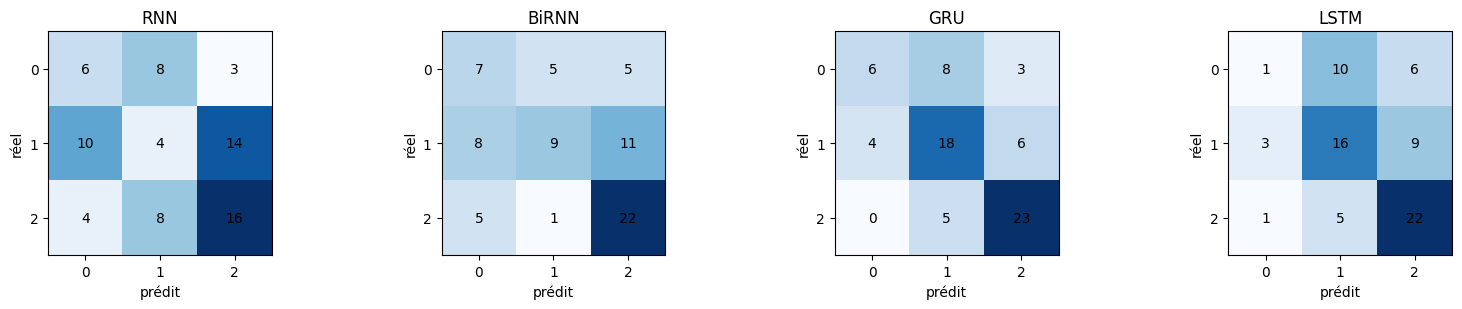

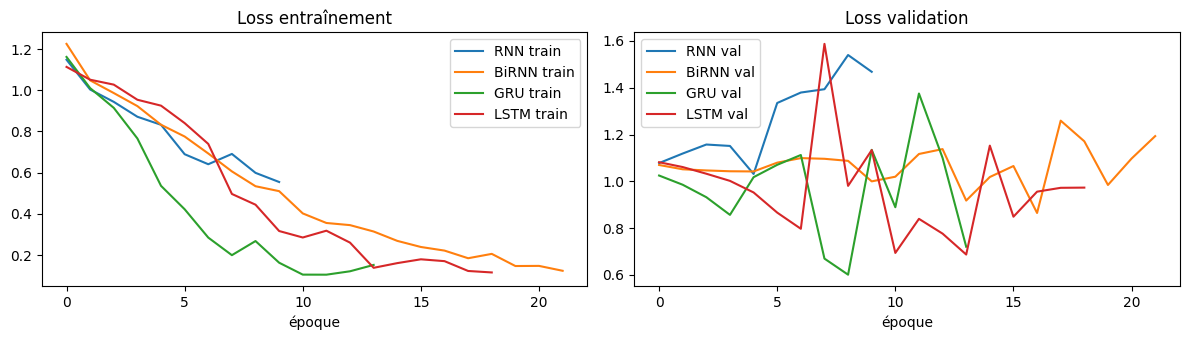

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (arch, cm) in zip(axes, cms.items()):
    ax.imshow(cm, cmap="Blues"); ax.set_title(arch)
    ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
    ax.set_xlabel("prédit"); ax.set_ylabel("réel")
    for i in range(n_classes):
        for j in range(n_classes): ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.savefig("matrices_confusion.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for arch, info in meilleurs.items():
    axes[0].plot(info["hist"]["train_loss"], label=f"{arch} train"); axes[1].plot(info["hist"]["val_loss"], label=f"{arch} val")
axes[0].set_title("Loss entraînement"); axes[1].set_title("Loss validation")
for a in axes: a.set_xlabel("époque"); a.legend()
plt.tight_layout(); plt.savefig("courbes_loss.png", dpi=150); plt.show()

 on verifier est ce que vraiment GRU est performant ou il a otenu un bon resultat au hasard lors de l entrainement

In [22]:
# Robustesse : on réentraîne chaque modèle avec 5 graines et on donne moyenne ± écart-type
for arch, info in meilleurs.items():
    accs, f1s = [], []
    for seed in range(5):
        torch.manual_seed(seed)
        m, _, _, _ = entrainer(arch, **info["params"], epochs=30)
        _, a, f, _, _ = run_epoch(m, test_dl, crit)
        accs.append(a); f1s.append(f)
    print(f"{arch:<6} accuracy = {np.mean(accs):.3f} ± {np.std(accs):.3f}   F1 = {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")

RNN    accuracy = 0.403 ± 0.090   F1 = 0.396 ± 0.093
BiRNN  accuracy = 0.452 ± 0.040   F1 = 0.449 ± 0.042
GRU    accuracy = 0.510 ± 0.116   F1 = 0.484 ± 0.108
LSTM   accuracy = 0.488 ± 0.076   F1 = 0.454 ± 0.059


In [23]:
for arch, info in meilleurs.items():
    _, _, _, preds, trues = run_epoch(info["model"], test_dl, crit)
    t = te_df[["article"]].copy(); t["pred"] = preds; t["true"] = trues
    agg = t.groupby("article").agg(true=("true", "first"), pred=("pred", lambda s: s.mode()[0]))
    print(f"{arch:<6} accuracy par article : {(agg.true == agg.pred).mean():.2f} sur {len(agg)} articles")

RNN    accuracy par article : 0.44 sur 9 articles
BiRNN  accuracy par article : 0.67 sur 9 articles
GRU    accuracy par article : 0.67 sur 9 articles
LSTM   accuracy par article : 0.67 sur 9 articles


RNN : environ 4 articles correctement classés sur 9.



BiRNN : 6 articles correctement classés sur 9.



GRU : 6 articles correctement classés sur 9.



LSTM : 6 articles correctement classés sur 9.

Sur les 9 articles du jeu de test, le RNN obtient une accuracy de 44 %, tandis que les architectures BiRNN, GRU et LSTM atteignent chacune 67 %.

Ces résultats montrent que les architectures bidirectionnelle et à portes (GRU et LSTM) obtiennent de meilleures performances que le RNN classique dans cette expérience.

Toutefois, le nombre limité d'articles du jeu de test (9) ne permet pas de tirer des conclusions définitives. Des évaluations sur un corpus plus important seraient nécessaires pour confirmer ces résultats.

## 7. Modèles de langue et score BLEU
Le score **BLEU** mesure la ressemblance entre un texte *généré* et un texte de référence : il n'a pas de sens pour une classification. L'énoncé demande donc d'évaluer les modèles comme **modèles de langue** (prédiction du mot suivant) : on entraîne RNN, GRU et LSTM en génération, on calcule la **perplexité** et le **BLEU** sur le test.


In [24]:
variables = [
    "vocab_size", "stoi", "itos",
    "train_dl", "val_dl", "test_dl",
    "te_df", "device", "SEED", "VARIANTE"
]

for v in variables:
    print(v, "OK" if v in globals() else "MANQUANTE")

vocab_size OK
stoi OK
itos OK
train_dl OK
val_dl OK
test_dl OK
te_df OK
device OK
SEED OK
VARIANTE OK



vocab_size	: Nombre de mots dans le vocabulaire.

stoi: Associe chaque mot à un identifiant numérique (String to Integer).

itos : Associe chaque identifiant numérique à son mot (Integer to String).

train_dl : Fournit les données pour entraîner le modèle.

val_dl: Fournit les données pour suivre les performances pendant l'entraînement.

test_dl	: Fournit les données pour évaluer le modèle final.

te_df : Contient les articles du jeu de test.

device :Indique si le calcul utilise le CPU ou le GPU.

SEED: Graine aléatoire pour rendre les expériences reproductibles.

VARIANTE :	Indique la représentation textuelle utilisée : tokens, stemming ou lemmatisation.

In [25]:
print("df existe :", "df" in globals())

if "df" in globals():
    print("Dimensions :", df.shape)
    print("Colonnes :", df.columns.tolist())

df existe : True
Dimensions : (55, 10)
Colonnes : ['Site', 'URL', 'Text', 'Score', 'Classe', 'label', 'Score_auto', 'tokens', 'tokens_stem', 'tokens_lemma']


Modélisation du langage : le modèle reçoit une séquence de mots et essaie de prédire les mots qui viennent ensuite.

Remarque  

- Le score BLEU compare le texte généré par le modèle avec un texte de référence
-

In [28]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

# definie l architecture du modele de language
class ModeleLangue(nn.Module):
    def __init__(self, vocab_size, cell="LSTM", emb_dim=128, hidden=256, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.rnn = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[cell](emb_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout); self.fc = nn.Linear(hidden, vocab_size)
    def forward(self, x, h=None):
        o, h = self.rnn(self.drop(self.emb(x)), h)
        return self.fc(self.drop(o)), h

def lm_epoch(model, loader, opt=None):
    train = opt is not None; model.train(train); tot, n = 0.0, 0
    crit = nn.CrossEntropyLoss(ignore_index=0)
    with torch.set_grad_enabled(train):
        for x, l, _ in loader:
            x = x.to(device)
            logits, _ = model(x[:, :-1])
            loss = crit(logits.reshape(-1, vocab_size), x[:, 1:].reshape(-1))
            if train:
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            tot += loss.item(); n += 1
    return tot / max(n, 1)

@torch.no_grad()
def generer_tokens(model, prompt_ids, n_new, sample=False, temperature=0.8, top_k=20):
    model.eval()
    x = torch.tensor([prompt_ids], device=device)
    logits, h = model(x)
    out = []
    for _ in range(n_new):
        l = logits[0, -1].clone()
        l[0] = -1e9; l[1] = -1e9                     # interdit <PAD> et <UNK>
        if sample:
            topv, topi = torch.topk(l / temperature, top_k)
            nxt = topi[torch.multinomial(torch.softmax(topv, dim=-1), 1)].item()
        else:
            nxt = l.argmax().item()                  # greedy (pour le calcul du BLEU, déterministe)
        out.append(nxt)
        logits, h = model(torch.tensor([[nxt]], device=device), h)
    return out

LM_EPOCHS, PROMPT_LEN, GEN_LEN = 20, 8, 20 # le modèle reçoit les 8 premiers mots de l'article , génère 20 mots supplémentaires
smooth = SmoothingFunction().method1
lm_resultats = []
for cell in ["RNN", "GRU", "LSTM"]: # boucle entraine successivement 3 modeles
    torch.manual_seed(SEED)
    lm = ModeleLangue(vocab_size, cell).to(device)
    opt = torch.optim.Adam(lm.parameters(), lr=2e-3)
    best_vl, best_state = 1e9, None
    for ep in range(LM_EPOCHS):
        lm_epoch(lm, train_dl, opt); vl = lm_epoch(lm, val_dl)
        if vl < best_vl: best_vl, best_state = vl, copy.deepcopy(lm.state_dict())
    lm.load_state_dict(best_state)
    test_loss = lm_epoch(lm, test_dl)

    b1, b2 = [], []
    for toks in te_df["tokens"]:
        ids_ = [stoi.get(w, 1) for w in toks]
        if len(ids_) < PROMPT_LEN + GEN_LEN: continue
        ref = [itos[i] for i in ids_[PROMPT_LEN:PROMPT_LEN + GEN_LEN]]
        hyp = [itos[i] for i in generer_tokens(lm, ids_[:PROMPT_LEN], GEN_LEN)]
        b1.append(sentence_bleu([ref], hyp, weights=(1, 0), smoothing_function=smooth))  # Calcul des scores BLEU-1
        b2.append(sentence_bleu([ref], hyp, weights=(0.5, 0.5), smoothing_function=smooth)) #  et BLEU-2
    lm_resultats.append({"Modèle": cell, "Perplexité (test)": float(np.exp(test_loss)),
                         "BLEU-1": np.mean(b1) if b1 else np.nan, "BLEU-2": np.mean(b2) if b2 else np.nan})
    print(cell, "terminé")

lm_table = pd.DataFrame(lm_resultats).set_index("Modèle").round(3)
lm_table.to_csv("resultats_bleu_modeles_langue.csv"); display(lm_table)

RNN terminé
GRU terminé
LSTM terminé


,Perplexité (test),BLEU-1,BLEU-2
Modèle,,,
RNN,571.275,0.029,0.010
GRU,566.717,0.020,0.009
LSTM,556.885,0.025,0.011


Pour chaque modèle :
1. Initialisation du modèle.
2. Entraînement sur train_dl.
3. Évaluation sur val_dl.
4. Conservation de la meilleure version selon la perte de validation.
5. Évaluation finale sur test_dl.
Le but est de comparer les capacités des trois architectures à apprendre le langage

La perplexité mesure à quel point le modèle est incertain lorsqu'il prédit les prochains mots.
- Perplexité faible : le modèle prédit généralement mieux les prochains mots.
- Perplexité élevée : le modèle éprouve davantage de difficultés.

Après avoir interdit les symboles <UNK> et <PAD> à la génération, les scores BLEU des trois modèles de langue sont très faibles (BLEU-1 entre 0,02 et 0,03 ; BLEU-2 environ 0,01) et leurs perplexités sont voisines (557 à 571). Les trois architectures ne se distinguent pas sur ce corpus de petite taille. »

In [30]:
toks = te_df["tokens"].iloc[0]
ids_ = [stoi.get(w, 1) for w in toks]
print("Prompt    :", " ".join(itos[i] for i in ids_[:PROMPT_LEN]))
print("Référence :", " ".join(itos[i] for i in ids_[PROMPT_LEN:PROMPT_LEN + GEN_LEN]))
print("Généré    :", " ".join(itos[i] for i in generer_tokens(lm, ids_[:PROMPT_LEN], GEN_LEN,
                                                              sample=True, temperature=1.2, top_k=50)))

Prompt    : ذكء صطناع اثر قصد كبر توقع <UNK> <UNK>
Référence : علم اليوم رحل تحل تكنولوجي سرع تقد تقن ذكء صطناع بتت <UNK> خلف فصل حية واع ومع وسع سارع صبح
Généré    : حول علج عمل عها قيد طرق جهز عمل حلل بين حلل ذكء صطناع ولد خبر طور حقق نبو تمت حلل


# Partie 2 — Transformer : fine-tuning de GPT-2 et génération

**Choix du modèle** : le tutoriel du sujet utilise `gpt2` (anglais) et la bibliothèque `pytorch-transformers`, aujourd'hui remplacée par **`transformers`**. Ton corpus est en arabe, donc on charge un GPT-2 **pré-entraîné en arabe** : `aubmindlab/aragpt2-base`. On  remplace `MODEL_NAME` par `"gpt2"`
**Corpus** : on utilise le texte **brut** de tes articles pertinents (pas de stop words retirés, pas de stemming : GPT-2 doit voir de vraies phrases).

In [34]:
from transformers import AutoTokenizer, AutoModelForCausalLM, get_linear_schedule_with_warmup

MODEL_NAME = "aubmindlab/aragpt2-base"
BLOCK, BS_GPT, EPOCHS_GPT, LR_GPT, WARMUP = 256, 4, 5, 5e-5, 20

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
if tok.pad_token is None: tok.pad_token = tok.eos_token

def texte_pour_gpt(t):
    t = supprimer_bruit(t)
    return re.sub(r"\s+", " ", t).strip()

# corpus : articles pertinents (score >= 7), split par article comme avant
corpus_train = [texte_pour_gpt(t) for t in df.loc[df.index.isin(tr_ids) & (df.Score >= 7), "Text"]]
corpus_eval  = [texte_pour_gpt(t) for t in df.loc[df.index.isin(list(va_ids) + list(te_ids)) & (df.Score >= 7), "Text"]]
print("Articles train / eval :", len(corpus_train), len(corpus_eval))

def make_blocks(texts, tok, block=BLOCK):
    ids_ = []
    for t in texts: ids_ += tok.encode(t) + [tok.eos_token_id]
    n = len(ids_) // block
    return torch.tensor(ids_[:n * block]).view(n, block)

train_blocks, eval_blocks = make_blocks(corpus_train, tok), make_blocks(corpus_eval, tok)
print("Blocs train / eval :", tuple(train_blocks.shape), tuple(eval_blocks.shape))

Articles train / eval : 14 6
Blocs train / eval : (150, 256) (80, 256)


In [35]:
@torch.no_grad()
def perplexite(model, blocks, bs=4):
    model.eval(); tot, n = 0.0, 0
    for i in range(0, len(blocks), bs):
        b = blocks[i:i + bs].to(device)
        tot += model(input_ids=b, labels=b).loss.item(); n += 1
    return float(np.exp(tot / max(n, 1)))

def finetune(model, blocks, epochs=EPOCHS_GPT, bs=BS_GPT, lr=LR_GPT, warmup=WARMUP):
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    steps = epochs * ((len(blocks) + bs - 1) // bs)
    sched = get_linear_schedule_with_warmup(opt, warmup, steps)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(blocks)); tot = 0.0
        for i in range(0, len(blocks), bs):
            b = blocks[perm[i:i + bs]].to(device)
            loss = model(input_ids=b, labels=b).loss
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad(); tot += loss.item()
        print(f"Époque {ep + 1}/{epochs} — loss moyenne : {tot / ((len(blocks) + bs - 1) // bs):.3f}")
    return model

@torch.no_grad()
def generer(model, tok, prompt, max_new_tokens=80, sample=True):
    model.eval()
    ids_ = tok(prompt, return_tensors="pt").input_ids.to(device)
    kw = dict(do_sample=True, top_k=50, top_p=0.95, temperature=0.8) if sample else dict(do_sample=False)
    out = model.generate(ids_, max_new_tokens=max_new_tokens, no_repeat_ngram_size=3,
                         pad_token_id=tok.eos_token_id, **kw)
    return tok.decode(out[0], skip_special_tokens=True)

def bleu_gpt(model, tok, blocks, n_ex=20, prompt_len=16, gen_len=32):
    """BLEU mot-à-mot : on donne le début d'un bloc réel et on compare la suite générée (greedy) à la vraie suite."""
    scores = []
    for b in blocks[:n_ex]:
        ids_ = b.tolist()
        prompt = tok.decode(ids_[:prompt_len], skip_special_tokens=True)
        ref = tok.decode(ids_[prompt_len:prompt_len + gen_len], skip_special_tokens=True).split()
        full = generer(model, tok, prompt, max_new_tokens=gen_len, sample=False)
        hyp = full[len(prompt):].split()
        scores.append(sentence_bleu([ref], hyp, weights=(0.5, 0.5), smoothing_function=smooth))
    return float(np.mean(scores)) if scores else float("nan")

In [36]:
model_gpt = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)

# AVANT fine-tuning (référence)
ppl_avant  = perplexite(model_gpt, eval_blocks)
bleu_avant = bleu_gpt(model_gpt, tok, eval_blocks)
print(f"Avant fine-tuning : perplexité={ppl_avant:.1f}  BLEU-2={bleu_avant:.3f}")

# Fine-tuning
model_gpt = finetune(model_gpt, train_blocks)

# APRÈS
ppl_apres  = perplexite(model_gpt, eval_blocks)
bleu_apres = bleu_gpt(model_gpt, tok, eval_blocks)
print(f"Après fine-tuning : perplexité={ppl_apres:.1f}  BLEU-2={bleu_apres:.3f}")

model_gpt.save_pretrained("gpt2_arabe_finetune"); tok.save_pretrained("gpt2_arabe_finetune")
pd.DataFrame({"": ["avant", "après"], "perplexité": [ppl_avant, ppl_apres], "BLEU-2": [bleu_avant, bleu_apres]}).to_csv("resultats_gpt2.csv", index=False)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                         | Status     |  | 
----------------------------+------------+--+-
h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Avant fine-tuning : perplexité=315.6  BLEU-2=0.007
Époque 1/5 — loss moyenne : 7.546
Époque 2/5 — loss moyenne : 5.435
Époque 3/5 — loss moyenne : 4.869
Époque 4/5 — loss moyenne : 4.608
Époque 5/5 — loss moyenne : 4.478
Après fine-tuning : perplexité=93.5  BLEU-2=0.021


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

### Génération d'un paragraphe à partir d'une phrase donnée

In [37]:
phrases = ["الذكاء الاصطناعي في الطب", "يعتمد الذكاء الاصطناعي على", "تطبيقات الذكاء الاصطناعي في التعليم"]
for p in phrases:
    print("PROMPT :", p)
    print(generer(model_gpt, tok, p, max_new_tokens=100))
    print("-" * 80)

PROMPT : الذكاء الاصطناعي في الطب
الذكاء الاصطناعي في الطب، حيث اكتشف الباحثون أن هذا النوع من الأدوية يمكن أن يكون مفيدا في علاج أمراض معينة، ومنها أمراض القلب وأمراض القلب والأوعية الدموية ، وأمراض القلب والسكري، وأمراض العيون، إضافة إلى أمراض مختلفة مثل الزهايمر وأمراض القلب ، وأمراض الكبد ، وأمراض العيون ، وأمراض الكلى، كما أن الذكاء الاصطناعي يعزز من صحة الإنسان ويحسن من أداء الأعمال ويقلل من الاعتماد على الأطباء. لكن يجب الانتباه إلى أن الذكاء البشري ليس مجرد مجموعة من المجالات التي يمكن للإنسان أن ُدعمها في الحياة اليومية،
--------------------------------------------------------------------------------
PROMPT : يعتمد الذكاء الاصطناعي على
يعتمد الذكاء الاصطناعي على مجموعة من العناصر التي تعمل بالذكاء الاصطناعي ، مثل ما يلي: تعتمد خوارزميات الذكاء الاصطناعي في العديد من الأنظمة على خوارزميتها على إنشاء نماذج تشبه نماذج العمل، ومن أهم خوارزيمات تحاكي أنماط البيانات، وهي التي تسمح بالاستدلال على البيانات التي تعمل بها الآلات، مما يساعد على تحسين دقة البيانات. تعتمد خوارزمية الذكاء ا

## Synthèse

### 1. Ce que j'ai appris

Les principales compétences acquises sont :

- Collecter et nettoyer des textes arabes : suppression du bruit, normalisation, suppression des mots vides (Stop Words), stemming et lemmatisation.
- Transformer les textes en séquences d'indices numériques et utiliser les embeddings pour représenter les mots.
- Construire et entraîner différents modèles de classification avec PyTorch : RNN, BiRNN, GRU et LSTM.
- Comprendre la différence entre la classification de textes et la modélisation du langage.
- Utiliser un modèle Transformer pré-entraîné, AraGPT2, et effectuer son fine-tuning sur un corpus spécialisé.
- Évaluer les modèles à l'aide de métriques telles que Accuracy, Precision, Recall, F1-score, Perplexity et BLEU-2.

### 2. Résultats obtenus

**Classification des articles :**

Après le réglage des hyperparamètres, le modèle LSTM a obtenu le meilleur F1-score macro sur l'ensemble de validation, avec **0,823**.

Cependant, sur l'ensemble de test, le modèle GRU a obtenu les meilleurs résultats, avec un F1-score macro de **0,617** et une accuracy de **0,658**.

Cela montre que le meilleur résultat sur la validation ne garantit pas nécessairement la meilleure généralisation sur les nouvelles données.

**Fine-tuning d'AraGPT2 :**

Le fine-tuning du modèle AraGPT2 a permis d'améliorer ses performances :

- La perplexité est passée de 315,6 avant le fine-tuning à 93,5 après 5 époques.
- Le BLEU-2 est passé de 0,007 à 0,021.
- La loss d'entraînement a diminué progressivement de 7,546 à 4,478 pendant les 5 époques.

Ces résultats indiquent une meilleure adaptation du modèle à notre corpus. Les exemples de génération montrent qu'il peut produire des textes en rapport avec les sujets proposés, mais que des répétitions et des erreurs grammaticales persistent.

### 3. Limites du travail

Plusieurs limites ont été identifiées :

- La taille réduite du dataset, qui limite la capacité des modèles à généraliser.
- La subjectivité de la notation manuelle des articles.
- Le déséquilibre possible entre les classes, qui peut influencer les performances de classification.
- Les différences entre les résultats de validation et de test, qui montrent une généralisation encore perfectible.
- Le faible volume de textes utilisés pour le fine-tuning d'AraGPT2, avec seulement 14 articles pertinents pour l'entraînement.
- Les limites du BLEU-2, qui mesure le chevauchement lexical avec un texte de référence, mais ne reflète pas complètement la qualité sémantique d'un texte généré.
